In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 6. Evaluación estadística

Este capítulo evalúa los modelos con todas las familias de métricas que pide el enunciado (discriminación, calidad probabilística, umbral fijo y utilidad de negocio) y somete las diferencias a inferencia estadística. El objetivo es responder la pregunta P3, si el MLP aporta una mejora estadísticamente significativa sobre las líneas base, distinguiendo siempre entre significancia estadística y relevancia práctica.

Las curvas de las secciones 6.1 a 6.4 usan la semilla 13: en scikit-learn, el tier mayor (1.601.694 filas de entrenamiento) evaluado sobre la muestra de 202.511 filas del día 30, y en Spark el día 30 completo (4.218.938 filas). Como los conjuntos de prueba difieren, cada entorno se grafica en su propio panel.

In [2]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from metrics import calibration_curve_data, lift_and_gain
SK = ART / "sklearn" / "predictions"; SP = ART / "spark" / "predictions"
y_sk = np.load(SK / "mlp_tier2000000_seed13_y_test.npy")
p_sk = {n: np.load(SK / f"{m}_tier2000000_seed13_p_test.npy") for m, n in [("mlp", "MLP"), ("histgb", "HistGB"), ("sgd", "SGD")]}
y_sp = np.load(SP / "lr_seed13_y_test.npy")
p_sp = {n: np.load(SP / f"{m}_seed13_p_test.npy") for m, n in [("mlp", "MLP"), ("lr", "LR"), ("gbt", "GBT")]}
def paneles(titulos, tam=(10, 3.8)):
    fig, axes = plt.subplots(1, 2, figsize=tam)
    for a, t in zip(axes, titulos):
        a.grid(True, color="#d9d9d9", linewidth=0.6); a.set_axisbelow(True); a.set_title(t, fontsize=10)
        for s in ("top", "right"): a.spines[s].set_visible(False)
    return fig, axes

## 6.1 Discriminación: curvas ROC y PR

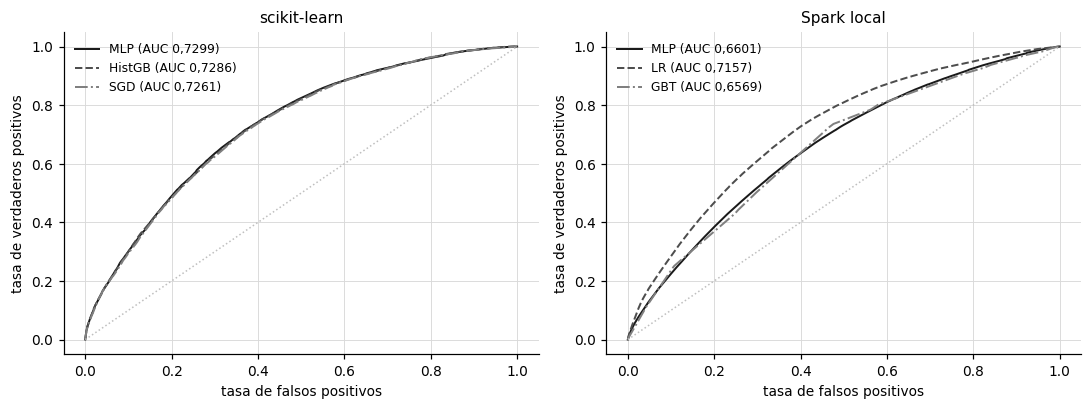

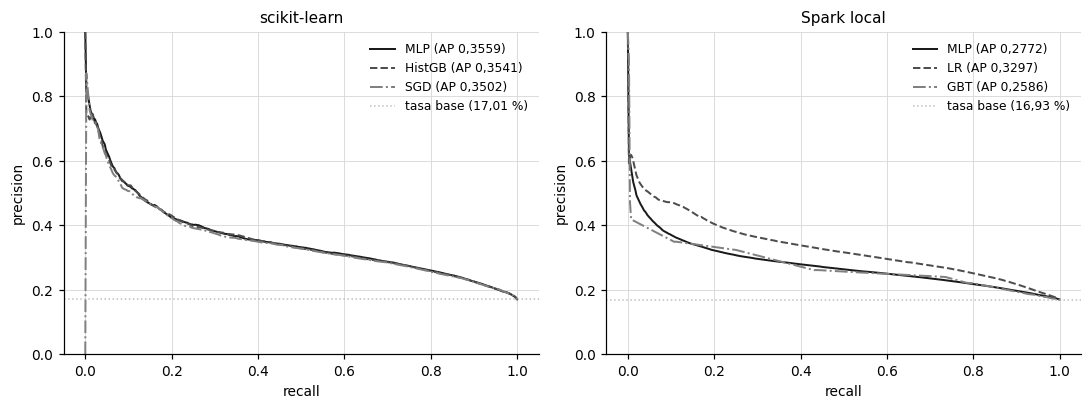

In [3]:
fig, (a1, a2) = paneles(["scikit-learn", "Spark local"])
for ax, y, P in ((a1, y_sk, p_sk), (a2, y_sp, p_sp)):
    grid = np.linspace(0, 1, 400)
    for (n, p), st in zip(P.items(), series_styles(3)):
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(grid, np.interp(grid, fpr, tpr), label=f"{n} (AUC {es(roc_auc_score(y, p), 4)})",
                color=st["color"], linestyle=st["linestyle"], linewidth=1.3)
    ax.plot([0, 1], [0, 1], color="#bfbfbf", linestyle=":", linewidth=1)
    ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

fig, (a1, a2) = paneles(["scikit-learn", "Spark local"])
for ax, y, P in ((a1, y_sk, p_sk), (a2, y_sp, p_sp)):
    grid = np.linspace(0, 1, 400)
    for (n, p), st in zip(P.items(), series_styles(3)):
        prec, rec, _ = precision_recall_curve(y, p)
        ax.plot(grid, np.interp(grid, rec[::-1], prec[::-1]), label=f"{n} (AP {es(average_precision_score(y, p), 4)})",
                color=st["color"], linestyle=st["linestyle"], linewidth=1.3)
    ax.axhline(y.mean(), color="#bfbfbf", linestyle=":", linewidth=1, label=f"tasa base ({es(100 * y.mean(), 2)} %)")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación.** En scikit-learn, las tres curvas ROC son casi indistinguibles, con AUC de 0,7299 para el MLP, 0,7286 para HistGB y 0,7261 para SGD en la semilla 13. En Spark, la regresión logística (0,7157) se separa con claridad del MLP (0,6601) y del árbol (0,6569), y la separación es visible en todo el rango de tasas de falsos positivos. Las curvas de precision y recall muestran el mismo orden: la PR AUC promedio de las cinco semillas es 0,356 para el MLP de scikit-learn y 0,330 para la regresión logística de Spark, frente a una referencia de azar igual a la tasa base, de 0,170.

En ese sentido, todos los modelos discriminan claramente mejor que el azar, pero la distancia al azar en la curva PR es moderada: el mejor modelo duplica la precisión del azar sin alcanzar valores altos. Esto es propio del CTR, donde muchas impresiones con el mismo contexto terminan en clic o no por factores que las variables no capturan, y donde las columnas anonimizadas y la hora no entraron al modelo (capítulo 3).

En consecuencia, se decide basar la comparación entre modelos en el AUC con sus pruebas formales (sección 6.5), porque las diferencias dentro de scikit-learn, de una a cuatro milésimas, son demasiado pequeñas para leerlas en una gráfica.

## 6.2 Calidad probabilística y calibración

La curva de calibración agrupa las predicciones en 10 intervalos de igual ancho y compara, en cada uno, la probabilidad media predicha con la fracción observada de clics. El error de calibración esperado resume esa distancia ponderada por el tamaño de cada intervalo {cite}`naeini2015obtaining`:

$$\mathrm{ECE} = \sum_{b=1}^{B} \frac{n_b}{N}\, \left|\, \bar y_b - \bar p_b \,\right| ,$$

y el puntaje de Brier es el error cuadrático medio de la probabilidad, $\frac{1}{N}\sum_i (p_i - y_i)^2$ {cite}`brier1950verification`.

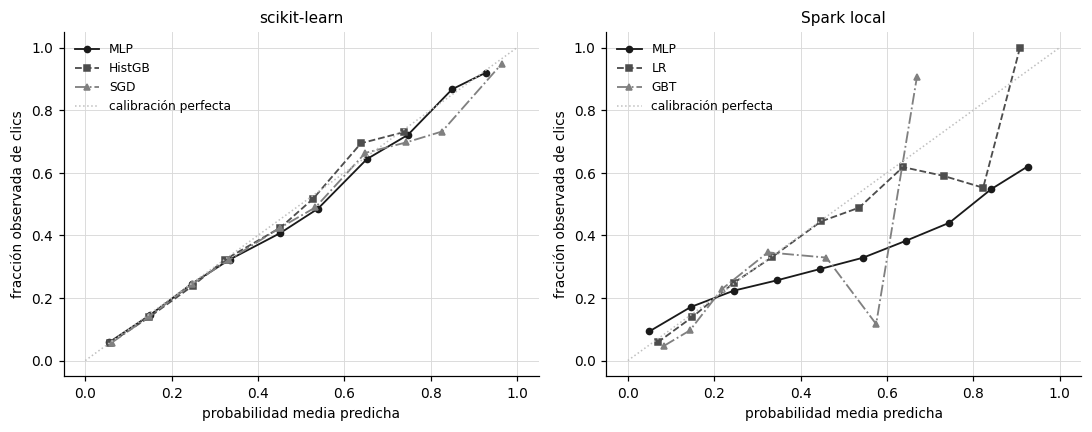

entorno,modelo,log loss,Brier,ECE
Spark,GBT,"0,4372","0,1354","0,0289"
Spark,LR,"0,4131","0,1286","0,0082"
Spark,MLP,"0,4464","0,1381","0,0469"
scikit-learn,HistGB,"0,4071","0,1272","0,0075"
scikit-learn,MLP,"0,4067","0,1270","0,0089"
scikit-learn,SGD,"0,4085","0,1275","0,0073"


In [4]:
fig, (a1, a2) = paneles(["scikit-learn", "Spark local"], (10, 4))
for ax, y, P in ((a1, y_sk, p_sk), (a2, y_sp, p_sp)):
    for (n, p), st in zip(P.items(), series_styles(3)):
        mp, fp = calibration_curve_data(y, p, n_bins=10)
        ax.plot(mp, fp, label=n, color=st["color"], linestyle=st["linestyle"], marker=st["marker"], markersize=4, linewidth=1.2)
    ax.plot([0, 1], [0, 1], color="#bfbfbf", linestyle=":", linewidth=1, label="calibración perfecta")
    ax.set_xlabel("probabilidad media predicha"); ax.set_ylabel("fracción observada de clics"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
sk = pd.read_csv(ART / "stats" / "sklearn_agregado.csv").query("tier == 2000000")
sp = pd.read_csv(ART / "stats" / "spark_agregado.csv")
sk["entorno"] = "scikit-learn"; sp["entorno"] = "Spark"
t = pd.concat([sk, sp]).query("metrica in ['log_loss', 'brier', 'ece']").pivot_table(index=["entorno", "model"], columns="metrica", values="media").reset_index()
t["model"] = t["model"].map({"mlp": "MLP", "histgb": "HistGB", "sgd": "SGD", "lr": "LR", "gbt": "GBT"})
tabla(t.rename(columns={"model": "modelo", "log_loss": "log loss", "brier": "Brier", "ece": "ECE"})[["entorno", "modelo", "log loss", "Brier", "ECE"]], d=4)

**Interpretación.** Los tres modelos de scikit-learn y la regresión logística de Spark están bien calibrados, con ECE entre 0,0073 y 0,0089, y sus curvas siguen de cerca la diagonal en el rango donde se concentran las predicciones, por debajo de 0,5. El MLP y el árbol de Spark están peor calibrados, con ECE de 0,0469 y 0,0289, y son también los de mayor log loss (0,446 y 0,437) y mayor Brier (0,138 y 0,135). En scikit-learn el MLP tiene el menor log loss (0,4067) pero no el menor ECE, que corresponde a SGD (0,0073).

Lo anterior indica que la regularización por parada temprana del MLP de scikit-learn y la pérdida logística de la regresión producen probabilidades confiables sin recalibración. El MLP de Spark, en cambio, es sobreconfiado en ambos extremos: en el intervalo de 0,9 a 1 predice en promedio 0,926, cuando la fracción observada de clics es 0,620, y en el de 0 a 0,1 predice 0,049 frente a 0,093 observado. Es el patrón esperable de una red sin regularización, entrenada con solo 300 mil filas. El árbol de Spark tiene el problema opuesto: con solo 5 variables de baja cardinalidad, sus predicciones se concentran entre 0,1 y 0,3 y casi no usan el resto de la escala. Hay que tener en cuenta que el CTR de la prueba (16,9 %) es algo menor que el de entrenamiento (17,1 %), así que una parte pequeña del ECE se debe a la deriva entre días y no al modelo.

Por ello, se recomienda usar las probabilidades del MLP de scikit-learn y de la regresión logística tal como salen, por ejemplo para pujar en una subasta de anuncios, donde importa el valor de la probabilidad y no solo el orden. Las del MLP y el árbol de Spark requerirían una recalibración, isotónica o de Platt, ajustada en validación antes de usarse.

## 6.3 Métricas con umbral fijo

El umbral de cada corrida de scikit-learn se eligió en validación maximizando F1 y se congeló antes de evaluar en prueba. La tabla promedia las cinco semillas del tier mayor, y la matriz de confusión corresponde al MLP con la semilla 13.

In [5]:
runs = pd.read_csv(ART / "sklearn" / "runs.csv").query("tier == 2000000")
u = runs.groupby("model")[["threshold", "accuracy", "precision", "recall", "f1"]].mean().reset_index()
u["model"] = u["model"].map({"mlp": "MLP", "histgb": "HistGB", "sgd": "SGD"})
tabla(u.rename(columns={"model": "modelo", "threshold": "umbral"}), d=4)
r = runs.query("model == 'mlp' and seed == 13").iloc[0]
cm = pd.DataFrame([["real: no clic", int(r["tn"]), int(r["fp"])], ["real: clic", int(r["fn"]), int(r["tp"])]],
                  columns=["", "predicho: no clic", "predicho: clic"])
print(f"Matriz de confusión del MLP, semilla 13, umbral {es(r['threshold'], 4)}:")
tabla(cm)

modelo,umbral,accuracy,precision,recall,f1
HistGB,"0,2188","0,6849","0,2997","0,6372","0,4076"
MLP,"0,2089","0,6779","0,2977","0,6576","0,4099"
SGD,"0,2083","0,6777","0,2955","0,6452","0,4052"


Matriz de confusión del MLP, semilla 13, umbral 0,2062:


,predicho: no clic,predicho: clic
real: no clic,114.169,53.893
real: clic,11.697,22.752


**Interpretación.** Los umbrales óptimos para F1 están entre 0,208 y 0,219, muy por debajo de 0,5, y producen F1 de 0,410 para el MLP, 0,408 para HistGB y 0,405 para SGD. Con su umbral de 0,206, el MLP de la semilla 13 detecta 22.752 de los 34.449 clics de la prueba (recall de 66,0 %) a cambio de 53.893 falsos positivos, con una precisión de 29,7 %. HistGB tiene el mayor accuracy (68,5 %) y el MLP el mayor recall (65,8 % en promedio).

Esto significa que, con una tasa base de 17 %, maximizar F1 exige un umbral cercano a la tasa base: el modelo acepta predecir clic para cualquier impresión con una probabilidad algo mayor que el promedio. Las diferencias de accuracy entre modelos no reflejan su capacidad de ordenar, sino dónde cayó su umbral: el MLP tiene un umbral más bajo que HistGB (0,209 frente a 0,219), predice más positivos, gana recall y pierde accuracy.

Por esta razón, lo indicado es elegir el umbral según el costo del error en el uso concreto, no según el accuracy. En una campaña donde un falso positivo cuesta poco, el umbral de F1 es razonable; si mostrar el anuncio tiene un costo alto, el umbral debe subir, con menor recall y mayor precisión.

## 6.4 Utilidad de negocio: lift y ganancia acumulada

Las impresiones se ordenan de mayor a menor probabilidad predicha y se dividen en deciles. La ganancia acumulada de un decil es la fracción de todos los clics que se captura al mostrar el anuncio solo hasta ese decil, y el *lift* es la razón entre el CTR del grupo seleccionado y la tasa base.

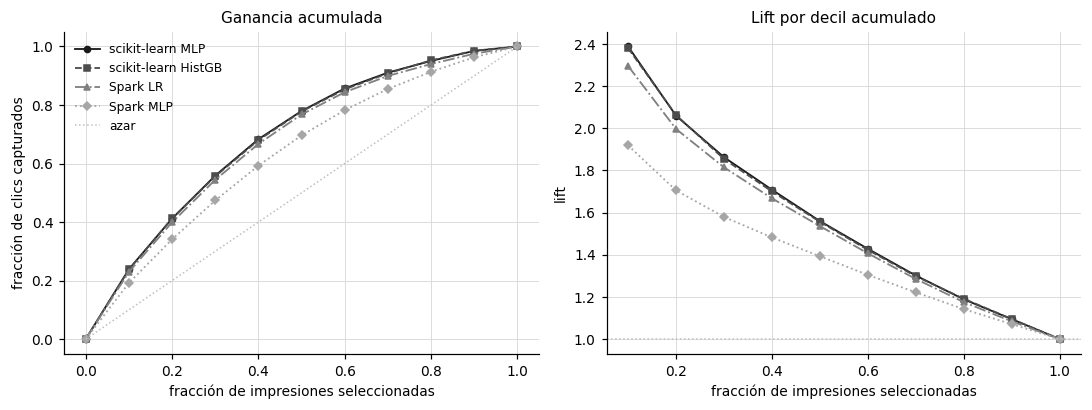

modelo,ganancia en el 10 % superior,lift en el 10 % superior,ganancia en el 30 % superior
scikit-learn MLP,"0,239","2,387","0,559"
scikit-learn HistGB,"0,238","2,379","0,556"
Spark LR,"0,229","2,295","0,544"
Spark MLP,"0,192","1,918","0,474"


In [6]:
fig, (a1, a2) = paneles(["Ganancia acumulada", "Lift por decil acumulado"])
series = [("scikit-learn MLP", y_sk, p_sk["MLP"]), ("scikit-learn HistGB", y_sk, p_sk["HistGB"]),
          ("Spark LR", y_sp, p_sp["LR"]), ("Spark MLP", y_sp, p_sp["MLP"])]
filas = []
for (n, y, p), st in zip(series, series_styles(4)):
    lg = pd.DataFrame(lift_and_gain(y, p))
    a1.plot([0] + list(lg["cobertura"]), [0] + list(lg["ganancia_acumulada"]), label=n, color=st["color"], linestyle=st["linestyle"], marker=st["marker"], markersize=4, linewidth=1.2)
    a2.plot(lg["cobertura"], lg["lift"], label=n, color=st["color"], linestyle=st["linestyle"], marker=st["marker"], markersize=4, linewidth=1.2)
    filas.append((n, lg["ganancia_acumulada"][0], lg["lift"][0], lg["ganancia_acumulada"][2]))
a1.plot([0, 1], [0, 1], color="#bfbfbf", linestyle=":", linewidth=1, label="azar")
a2.axhline(1, color="#bfbfbf", linestyle=":", linewidth=1)
a1.set_xlabel("fracción de impresiones seleccionadas"); a1.set_ylabel("fracción de clics capturados")
a2.set_xlabel("fracción de impresiones seleccionadas"); a2.set_ylabel("lift")
a1.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
tabla(pd.DataFrame(filas, columns=["modelo", "ganancia en el 10 % superior", "lift en el 10 % superior", "ganancia en el 30 % superior"]), d=3)

**Interpretación.** Con el MLP de scikit-learn, el 10 % de impresiones con mayor probabilidad concentra el 23,9 % de los clics, un lift de 2,39, y el 30 % superior concentra el 55,9 %. HistGB queda prácticamente igual (23,8 % y 2,38), la regresión logística de Spark algo por debajo (23,0 % y 2,30), y el MLP de Spark es el más bajo, con 19,2 % y un lift de 1,92.

De esta forma, la diferencia de AUC entre el mejor modelo de cada entorno, unos 1,5 puntos en promedio (0,731 frente a 0,716), se traduce en menos de un punto porcentual de clics capturados en el primer decil. En cambio, los 7 puntos de AUC que separan los dos MLP equivalen a 4,7 puntos de clics capturados: al mostrar el anuncio al mismo 10 % del tráfico, el MLP de scikit-learn encuentra un 24 % más de clics que el de Spark.

Así las cosas, se propone usar la curva de ganancia para traducir las diferencias de AUC a la decisión de negocio. Para una campaña que solo puede pagar el 10 % de las impresiones, cualquiera de los modelos de scikit-learn o la regresión logística de Spark sirve; el MLP de Spark, en las condiciones en que se pudo entrenar, no.

## 6.5 Inferencia estadística

### Diseño de las pruebas

Se aplican dos niveles de inferencia, que responden preguntas distintas.

- **Entre semillas.** La unidad de independencia es la semilla, con 5 observaciones del AUC por modelo. Las diferencias se prueban con la $t$ de Welch {cite}`welch1947generalization`, la equivalencia con TOST {cite}`schuirmann1987comparison` y el margen $\delta = 0{,}01$, y el tamaño del efecto con la $d$ de Cohen {cite}`cohen1988statistical`. Este nivel incorpora la variabilidad del entrenamiento: la muestra de filas, la inicialización y el orden de los minilotes.
- **Dentro de una semilla.** Sobre el mismo conjunto de prueba, el AUC de dos modelos se compara con la prueba de DeLong pareada {cite}`delong1988comparing`, implementada con el algoritmo rápido por *midranks* {cite}`sun2014fast`, que estima la covarianza entre ambos AUC a partir de los componentes estructurales de cada positivo y cada negativo. Las clasificaciones se comparan con McNemar {cite}`mcnemar1947note` sobre los pares discordantes. Este nivel solo incorpora la incertidumbre del muestreo de la prueba.

Los $p$-valores se ajustan con Holm {cite}`holm1979simple` dentro de cada familia. La normalidad del AUC entre semillas se verificó con Shapiro-Wilk {cite}`shapiro1965analysis`, aunque con 5 observaciones su potencia es muy baja. Wilcoxon no se usa, porque con 5 pares su $p$ mínimo bilateral es 0,0625 y nunca podría rechazar al 5 %. La validez de la implementación de DeLong se verificó con datos simulados: reproduce exactamente el AUC de scikit-learn y da $p = 1$ al comparar un modelo consigo mismo.

### Comparaciones entre semillas

In [7]:
s = pd.read_csv(ART / "stats" / "comparaciones_por_semilla.csv")
nom = {"mlp": "MLP", "histgb": "HistGB", "sgd": "SGD", "lr": "LR", "gbt": "GBT"}
s["comparación"] = [f"{ea} {nom[a]} vs {eb} {nom[b]}" for ea, a, eb, b in zip(s["entorno_a"], s["modelo_a"], s["entorno_b"], s["modelo_b"])]
cols = ["comparación", "diferencia_media", "d_cohen", "p_valor_welch", "p_valor_welch_holm", "p_valor_tost_holm", "mde_en_auc", "conclusion"]
tabla(s[cols].rename(columns={"diferencia_media": "diferencia de AUC", "d_cohen": "d de Cohen", "p_valor_welch": "p Welch",
                              "p_valor_welch_holm": "p Welch (Holm)", "p_valor_tost_holm": "p TOST (Holm)",
                              "mde_en_auc": "diferencia mínima detectable", "conclusion": "conclusión"}), d=4)

comparación,diferencia de AUC,d de Cohen,p Welch,p Welch (Holm),p TOST (Holm),diferencia mínima detectable,conclusión
sklearn MLP vs sklearn HistGB,"0,0018","1,6820","0,0500","0,1000","0,0004","0,0022",equivalente dentro de delta
sklearn MLP vs sklearn SGD,"0,0041","3,8210","0,0025","0,0076","0,0012","0,0022",diferencia significativa pero menor que delta (equivalencia practica)
spark MLP vs spark LR,"-0,0550","-15,9746","0,0000","0,0001","1,0000","0,0070",diferencia significativa
spark MLP vs spark GBT,"0,0041","1,1741","0,1363","0,1363","0,0784","0,0070",no concluyente (ni diferencia ni equivalencia con n=5)
sklearn MLP vs spark MLP,"0,0700","19,4317","0,0000","0,0000","1,0000","0,0073",diferencia significativa


**Interpretación.** En scikit-learn, el MLP supera a HistGB en 0,0018 de AUC y a SGD en 0,0041. Frente a HistGB, la diferencia no es significativa tras el ajuste de Holm ($p = 0{,}100$), pero la prueba TOST sí rechaza que la diferencia supere $\delta$ ($p = 0{,}0004$): los dos modelos son equivalentes en la práctica. Frente a SGD, la diferencia es significativa ($p = 0{,}0076$) y a la vez menor que $\delta$ ($p_{\text{TOST}} = 0{,}0012$). En Spark, el MLP es 0,055 peor que la regresión logística ($p < 0{,}0001$), y frente al árbol la comparación no es concluyente: ni la diferencia ($p = 0{,}136$) ni la equivalencia ($p = 0{,}078$) alcanzan significancia. Entre entornos, el MLP de scikit-learn supera al de Spark en 0,070.

Hay que tener en cuenta que, con 5 semillas por grupo y potencia de 0,8, la diferencia mínima detectable es $d = 2{,}02$ desviaciones estándar, lo que en AUC equivale a 0,0022 en scikit-learn y a unos 0,007 en Spark, donde el MLP varía más entre semillas. Por eso la diferencia de 0,0018 frente a HistGB, menor que la mínima detectable, no puede declararse distinta de cero con este diseño, pero sí puede acotarse dentro de $\delta$, porque las dos varianzas son muy pequeñas. Así mismo, la $d$ de Cohen es enorme en varias comparaciones (3,8 frente a SGD), porque la desviación estándar entre semillas es de milésimas: un efecto grande en desviaciones estándar puede ser pequeño en la escala del problema.

En síntesis, la respuesta a P3 es matizada. El MLP aporta una mejora estadísticamente significativa sobre la regresión logística en scikit-learn, pero de 0,4 puntos de AUC, menor que el margen de relevancia; frente al árbol potenciado es equivalente en la práctica. Por tanto, corresponde concluir que, con estas variables, la ventaja del MLP sobre líneas base bien afinadas es real pero pequeña.

### Prueba de DeLong pareada

In [8]:
d = pd.read_csv(ART / "stats" / "delong_pareado.csv")
d["par"] = d["entorno"] + ": " + d["modelo_a"].str.replace("_", " ") + " vs " + d["modelo_b"].str.replace("_", " ")
d["IC 95 % diferencia"] = [f"[{es(a)}; {es(b)}]" for a, b in zip(d["ic95_dif_low"], d["ic95_dif_high"])]
tabla(d[["par", "seed", "diferencia_auc", "IC 95 % diferencia", "correlacion_auc", "p_valor_holm"]].rename(
    columns={"seed": "semilla", "diferencia_auc": "diferencia de AUC", "correlacion_auc": "correlación entre AUC", "p_valor_holm": "p (Holm)"}), d=4)

par,semilla,diferencia de AUC,IC 95 % diferencia,correlación entre AUC,p (Holm)
sklearn: mlp vs histgb,13,"0,0013","[0,0005; 0,0020]","0,9637","0,0031"
sklearn: mlp vs sgd,13,"0,0038","[0,0030; 0,0046]","0,9614","0,0000"
spark: mlp vs lr,13,"-0,0556","[-0,0562; -0,0550]","0,6138","0,0000"
spark: mlp vs gbt,13,"0,0032","[0,0025; 0,0040]","0,3939","0,0000"
sklearn: mlp vs histgb,29,"0,0023","[0,0015; 0,0032]","0,9563","0,0000"
sklearn: mlp vs sgd,29,"0,0048","[0,0039; 0,0057]","0,9493","0,0000"
spark: mlp vs lr,29,"-0,0512","[-0,0518; -0,0507]","0,6520","0,0000"
spark: mlp vs gbt,29,"0,0078","[0,0070; 0,0085]","0,4301","0,0000"
sklearn: mlp vs histgb,47,"0,0036","[0,0027; 0,0044]","0,9510","0,0000"
sklearn: mlp vs sgd,47,"0,0059","[0,0050; 0,0069]","0,9425","0,0000"


**Interpretación.** Dentro de cada semilla, la ventaja del MLP de scikit-learn sobre HistGB va de 0,0008 a 0,0036 y es significativa en 4 de las 5 semillas; en la semilla 97 el intervalo incluye el cero ($p = 0{,}068$). Frente a SGD es significativa en las 5 semillas, entre 0,0030 y 0,0060. En Spark, el MLP pierde frente a la regresión logística entre 0,050 y 0,062 en todas las semillas, y frente al árbol las diferencias son significativas en cada semilla pero cambian de signo: el MLP gana en cuatro semillas y pierde en la 47 ($-0{,}0022$). La comparación pareada entre entornos, con el MLP de scikit-learn re-evaluado sobre el día 30 completo, da una diferencia de 0,0720, con intervalo [0,0714; 0,0725].

Esto quiere decir que la prueba de DeLong es mucho más sensible que la comparación entre semillas, por dos razones. Los AUC de dos modelos sobre la misma prueba están muy correlacionados (0,94 a 0,96 en scikit-learn), y DeLong descuenta esa covarianza al estimar la varianza de la diferencia, $\mathrm{Var}(\widehat{\mathrm{AUC}}_a - \widehat{\mathrm{AUC}}_b) = \sigma_a^2 + \sigma_b^2 - 2\sigma_{ab}$. Pero DeLong condiciona en el modelo entrenado: no ve la variabilidad entre semillas. El caso del MLP frente al árbol en Spark lo muestra con claridad, porque cada semilla da un resultado "significativo" y en sentidos opuestos.

Por lo anterior, conviene leer los dos niveles juntos: DeLong establece que, para un modelo ya entrenado, la diferencia en esta prueba no es azar del muestreo, y la comparación entre semillas establece si esa diferencia se sostiene al reentrenar. Solo cuando ambos coinciden, como en MLP frente a SGD en scikit-learn o en scikit-learn frente a Spark, se puede afirmar una diferencia robusta.

### Prueba de McNemar

En scikit-learn se usa el umbral de validación de cada corrida. Spark no guardó predicciones de validación, así que su umbral se fijó con una regla que solo depende del entrenamiento: la tasa base de clics de los días 21 a 28 (0,1714). En la comparación entre entornos, la misma regla se aplica a ambos modelos.

In [9]:
m = pd.read_csv(ART / "stats" / "mcnemar_pareado.csv")
m["par"] = m["entorno"] + ": " + m["modelo_a"].str.replace("_", " ") + " vs " + m["modelo_b"].str.replace("_", " ")
tabla(m[["par", "seed", "umbral", "acc_a", "acc_b", "solo_a_acierta", "solo_b_acierta", "p_valor_holm"]].rename(
    columns={"seed": "semilla", "acc_a": "accuracy A", "acc_b": "accuracy B", "solo_a_acierta": "solo A acierta",
             "solo_b_acierta": "solo B acierta", "p_valor_holm": "p (Holm)"}), d=4, enteros=("solo A acierta", "solo B acierta"))

par,semilla,umbral,accuracy A,accuracy B,solo A acierta,solo B acierta,p (Holm)
sklearn: mlp vs histgb,13,validacion,"0,6761","0,6918",5.221,8.396,"0,0000"
sklearn: mlp vs sgd,13,validacion,"0,6761","0,6657",7.305,5.198,"0,0000"
spark: mlp vs lr,13,tasa_base_train,"0,6339","0,6162",549.348,474.465,"0,0000"
spark: mlp vs gbt,13,tasa_base_train,"0,6339","0,5594",839.702,525.227,"0,0000"
sklearn: mlp vs histgb,29,validacion,"0,6749","0,6863",5.653,7.955,"0,0000"
sklearn: mlp vs sgd,29,validacion,"0,6749","0,6903",6.634,9.741,"0,0000"
spark: mlp vs lr,29,tasa_base_train,"0,6301","0,6162",513.239,454.250,"0,0000"
spark: mlp vs gbt,29,tasa_base_train,"0,6301","0,5665",791.246,522.939,"0,0000"
sklearn: mlp vs histgb,47,validacion,"0,6823","0,6918",5.720,7.639,"0,0000"
sklearn: mlp vs sgd,47,validacion,"0,6823","0,6695",9.208,6.613,"0,0000"


**Interpretación.** Todas las comparaciones de McNemar son significativas tras Holm, pero su dirección no siempre coincide con la del AUC. En scikit-learn, HistGB acierta más que el MLP en cuatro de cinco semillas, y frente a SGD el ganador cambia de semilla en semilla. En Spark, con el umbral de la tasa base, el MLP tiene mayor accuracy que la regresión logística (63,4 % frente a 61,6 % en la semilla 13), aunque su AUC es 5,6 puntos menor. Entre entornos ocurre lo mismo: el MLP de Spark acierta más que el de scikit-learn (63,4 % frente a 62,5 %).

Es decir, McNemar compara los errores de dos reglas de decisión, y el resultado depende tanto del umbral como del modelo. Con la tasa base como umbral, la regresión logística de Spark clasifica como clic al 46,3 % de las impresiones y el MLP solo al 39,6 %; con 83 % de negativos, el modelo que predice menos positivos gana accuracy aunque ordene peor. En scikit-learn, los umbrales se eligieron para maximizar F1, no el accuracy, así que el ganador de McNemar refleja dónde cayó cada umbral.

De ahí que se opte por usar McNemar solo para afirmar que dos modelos cometen errores distintos con un umbral dado, no para decidir cuál es mejor. La pregunta P3 se responde con el AUC, porque es la métrica primaria fijada a priori y no depende del umbral; McNemar se reporta porque el enunciado lo pide y porque muestra que la elección del umbral puede invertir una conclusión.